# EMQA_L6_neg_hours

**Negative day-ahead prices: number of hour-equivalents with a negative price per year in Romania, Bulgaria, Hungary and Germany-Luxembourg, 2022 to 2026-10-31 (2026 = Jan-Oct); a 15-min interval counts 0.25 h. Prints the counts of the last full year and the like-for-like January-cut-off counts.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_neg_hours/EMQA_L6_neg_hours.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Hour-equivalents with a negative price: H_y = sum over intervals of year y with p_t < 0 of the interval length dt_t (h).

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
hours = {z: {y: fl(PX['dur'][(LOC_YEAR == y) & (PX[z] < 0).values].sum(), 2) for y in YEARS} for z in ZONES}
lfl = {z: {y: fl(PX['dur'][(LOC_YEAR == y) & (PX.index.month <= END.month) & (PX[z] < 0).values].sum(), 2) for y in (Y - 1, Y)}
       for z in ZONES}
show_numbers({f'neg.hours.RO.{Y - 1}': hours['RO'][Y - 1], f'neg.hours.DE_LU.{Y - 1}': hours['DE_LU'][Y - 1],
              f'neg.lfl.RO.{Y - 1}': lfl['RO'][Y - 1], f'neg.lfl.RO.{Y}': lfl['RO'][Y],
              f'neg.lfl.HU.{Y - 1}': lfl['HU'][Y - 1], f'neg.lfl.HU.{Y}': lfl['HU'][Y]})

neg.hours.RO.2025                  196.0
neg.hours.DE_LU.2025               574.75
neg.lfl.RO.2025                    196.0
neg.lfl.RO.2026                    171.75
neg.lfl.HU.2025                    281.0
neg.lfl.HU.2026                    223.5


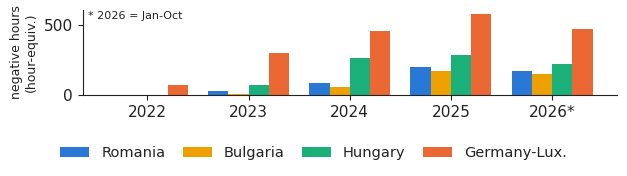

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 1.85))
yy = [y for y in YEARS if y >= 2022]
for i, z in enumerate(ZONES):
    ax.bar(np.arange(len(yy)) + (i - 1.5) * 0.2, [hours[z][y] for y in yy], width=0.2, color=PAL[z], label=ZN[z])
ax.set_xticks(range(len(yy)))
ax.set_xticklabels([str(y) + ('*' if y == Y else '') for y in yy])
ax.set_ylabel('negative hours\n(hour-equiv.)', fontsize=9)
ax.text(0.01, 0.9, YTD, transform=ax.transAxes, fontsize=8)
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('neg_hours.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()